In [83]:
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from typing import TypedDict,Literal
from pydantic import BaseModel,Field
from langchain.messages import SystemMessage,HumanMessage

In [94]:
generative_llm = ChatGroq(model='openai/gpt-oss-120b')
eval_llm = ChatGroq(model='openai/gpt-oss-120b')
optimizer_llm = ChatGroq(model='qwen/qwen3.8-27b')

In [85]:
class CodeBot(TypedDict):
    problem:str
    plan:str
    code:str
    evaluation:Literal['ready','need_improvement']
    iteration:int
    MAX_ITERATION:int


In [86]:
class EvaluationSchema(BaseModel):
    evaluation : Literal['ready','need_improvement'] = Field(description='this will tell us if our debate speech is on point or not')

In [92]:
def problem_understanding(state:CodeBot):
    message = [
        SystemMessage(content='you need to produce a good quality of code'),
        HumanMessage(content=f'''you need to understand the problem and think about the features that can be added and can improve the product that user si building
          the problem given by user is :{state['problem']}
            rules:
            1) do not go outside the topic 
            2) think only for feasible features that can be built 
            3) make a md file after completion 
            4)Also include the tech stack which technology we are using 
            

''')
    ]
    response =generative_llm.invoke(message).content
    return{'plan':response}

def coder(state:CodeBot):
    prompt = f"we have the plan for the certain problem :{state['plan']} now i want you to implement this and write code for it this is the {state['iteration']+1}"
    response = generative_llm.invoke(prompt).content
    return {
        'code': response,
        'iteration': state['iteration'] + 1
    }

def evaluate(state:CodeBot)->Literal['ready','need_improvement']:
    prompt =f"you are evalutor you check if the code:{state['code']} has any certain major bugs and is it ready to run by the user check for logic and then give the result"
    evaluate = eval_llm.with_structured_output(schema=EvaluationSchema).invoke(prompt).evaluation
    return {'evaluation':evaluate}
def optimizer(state:CodeBot):
    prompt = f"we have the evaluation result now make the changes so that the code is alright and according to the {state['plan']} and make sure all the changes are occuring and the main task is still the same"
    response = optimizer_llm.invoke(prompt)
    iteration = state['iteration'] + 1

    return{'Code':response,'iteration':iteration}
def checker(state: CodeBot):
    if (
        state['evaluation'] == 'ready'
        or state['iteration'] >= state['MAX_ITERATION']
    ):
        return 'approved'

    return 'need_improvement'

In [88]:
graph = StateGraph(CodeBot)

graph.add_node('problem',problem_understanding)

graph.add_node('generate_code',coder)

graph.add_node('evaluation',evaluate)

graph.add_node('optimization',optimizer)

graph.add_edge(START,'problem')

graph.add_edge('problem','generate_code')

graph.add_edge('generate_code','evaluation')

graph.add_conditional_edges('evaluation',checker,{'approved': END, 'need_improvement': 'optimization'})

graph.add_edge('optimization','evaluation')

workflow = graph.compile()


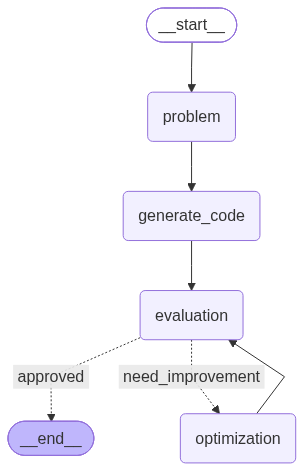

In [89]:
workflow

In [104]:
initial_state = {
    'problem': 'write a code to print fibonaaci series',
    'plan': '',
    'code': '',
    'evaluation': 'need_improvement',
    'iteration': 0,
    'MAX_ITERATION': 3
}

result = workflow.invoke(initial_state)

print(result)

{'problem': 'write a code to print fibonaaci series', 'plan': '## 📄 `FIBONACCI_SERIES.md`\n\n---  \n\n### 📝 Problem Statement  \nWrite a program that prints the Fibonacci series. The series starts with `0, 1` and each subsequent number is the sum of the two preceding ones.\n\n---\n\n### 💻 Tech Stack  \n\n| Component | Technology | Reason |\n|-----------|------------|--------|\n| **Language** | **Python 3.11+** | Simple syntax, built‑in big‑integer support, widely available. |\n| **CLI** | `argparse` (standard library) | Handles command‑line arguments cleanly without extra dependencies. |\n| **Testing** | `unittest` (standard library) | Guarantees correctness for edge cases. |\n| **Packaging (optional)** | `setuptools` | Allows the script to be installed as a console command. |\n\n> *All used technologies are part of the Python standard library – no external packages are required.*\n\n---\n\n### 🚀 Core Implementation  \n\n```python\n#!/usr/bin/env python3\n"""\nfib_series.py\n\nPrints t

In [105]:
print(result['code'])

Below is a **complete, ready‑to‑run** implementation that follows the design described in `FIBONACCI_SERIES.md`.  
Everything lives in a single package directory called **`fib_series`** so you can install it locally, run it as a script, or import the helpers in your own code.

---

## Directory layout

```
fib_series/
│
├─ fib_series/                # <-- Python package
│   ├─ __init__.py
│   ├─ cli.py                 # command‑line interface (main entry point)
│   └─ core.py                # core Fibonacci logic (iterative / recursive)
│
├─ tests/
│   └─ test_core.py           # unit‑tests for the core functions
│
├─ setup.cfg                  # optional packaging metadata
└─ README.md                  # short usage guide
```

> **Tip** – If you just want the script, you can copy `fib_series/cli.py` to a file called `fib_series.py` and run it directly. The package layout is shown here because it makes testing and future extensions easier.

---

## 1️⃣ `fib_series/core.py` – Core Fibon